# Evaluation dataset preparation

This notebook prepares the Steam reviews dataset (`data/external/recommendations.csv`, ~41M rows) for evaluating the recommender. The recommender represents each game as a feature vector and recommends games by cosine similarity to the profile of the games a user liked. To evaluate it, we need users with a history of liked games that the system can actually score.

## 1. Load the data and keep only positive reviews

The file is ~1.9 GB, so columns are loaded with compact dtypes (`int32`, `float32`, `bool`) to reduce memory usage. The dataset has no missing values, so no imputation is needed.

Only reviews with `is_recommended == True` are kept. A positive review is our signal that a user liked a game. Negative reviews would describe what the user *doesn't* want, which the similarity-based recommender does not use.

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../../../data/external/recommendations.csv")

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "app_id": "int32",
        "helpful": "int32",
        "funny": "int32",
        "is_recommended": "bool",
        "hours": "float32",
        "user_id": "int32",
        "review_id": "int32",
    },
    parse_dates=["date"],
)

# number of rows left after each step, plotted in the summary
step_sizes = {"All reviews": len(df)}

df = df[df["is_recommended"]]
step_sizes["Positive reviews only"] = len(df)
print(df.shape)

(35304398, 8)


## 2. Remove duplicate user–game pairs

A user appearing in many rows is expected, since each row is a review of a different game. However, the same user reviewing the **same game** more than once is a true duplicate and would count that game twice in the user's history. Only the first occurrence of each `(user_id, app_id)` pair is kept. This affects only a handful of rows.

In [2]:
df = df.drop_duplicates(["user_id", "app_id"])
step_sizes["Duplicates removed"] = len(df)
print(df.shape)

(35304383, 8)


## 3. Keep only games that have a feature vector

The recommender can only score games in `data/parquet/games_fully_vectorized.parquet`, the same file the backend loads in `src/backend/cosine_similarity.py`. Reviews of games outside that file are dropped. The backend skips unknown `appid`s without an error, so leaving them in would quietly make users' histories shorter than they look.

This step runs **before** the minimum-games filter, so every user who survives step 4 has enough games the system can use.

In [3]:
VECTORS_PATH = Path("../../../data/parquet/games_fully_vectorized.parquet")

vectorized_ids = pd.read_parquet(VECTORS_PATH, columns=["appid"])["appid"]
df = df[df["app_id"].isin(vectorized_ids)]
step_sizes["Games with a vector only"] = len(df)
print(df.shape)

(32995756, 8)


## 4. Keep only users with `MIN_GAMES_PER_USER` to `MAX_GAMES_PER_USER` liked games

Evaluation hides some of a user's liked games and checks whether the recommender suggests them from the rest. That requires enough history to split. Users with very few games (more than half of all users have only one review) cannot be evaluated this way, so only users with at least 4 liked games are kept.

Users with more than 10 liked games are dropped as well. In the app, a user enters only a handful of games, and averaging a long history into one profile gives a blurry centroid that does not reflect that use. Both bounds are inclusive.

In [4]:
MIN_GAMES_PER_USER = 4
MAX_GAMES_PER_USER = 10

games_per_user = df.groupby("user_id")["app_id"].transform("size")
df = df[games_per_user.between(MIN_GAMES_PER_USER, MAX_GAMES_PER_USER)].reset_index(drop=True)
step_sizes[f"Users with {MIN_GAMES_PER_USER}–{MAX_GAMES_PER_USER} games only"] = len(df)
print(df.shape)

(9410702, 8)


## 5. Summary of the final dataset

This cell prints the size of the prepared dataset, the number of unique users and games, the date range, and memory usage. It also prints:

- **density**: the share of the user × game matrix that is filled
- **games per user**: how much history each user has
- **users per game**: how popular each game is

Many games have only a few users, so popular games dominate the dataset.

The chart below shows how many rows are left after each step, as a share of the original dataset.

In [5]:
games_per_user = df.groupby("user_id").size()
users_per_game = df.groupby("app_id").size()

print(f"rows:          {len(df):,}")
print(f"unique users:  {df['user_id'].nunique():,}")
print(f"unique games:  {df['app_id'].nunique():,}")
print(f"date range:    {df['date'].min().date()} .. {df['date'].max().date()}")
print(f"memory:        {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
print(f"density:       {len(df) / (games_per_user.size * users_per_game.size):.6%}")
print("\ngames per user:")
print(games_per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print("\nusers per game:")
print(users_per_game.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print()
df.info()

rows:          9,410,702
unique users:  1,652,783
unique games:  29,965
date range:    2010-10-15 .. 2022-12-31
memory:        296 MB
density:       0.019002%

games per user:
count    1652783.00
mean           5.69
std            1.78
min            4.00
25%            4.00
50%            5.00
75%            7.00
90%            9.00
99%           10.00
max           10.00

users per game:
count    29965.00
mean       314.06
std       2053.51
min          1.00
25%          3.00
50%          8.00
75%         44.00
90%        284.60
99%       7274.72
max      90020.00

<class 'pandas.DataFrame'>
RangeIndex: 9410702 entries, 0 to 9410701
Data columns (total 8 columns):
 #   Column          Dtype         
---  ------          -----         
 0   app_id          int32         
 1   helpful         int32         
 2   funny           int32         
 3   date            datetime64[us]
 4   is_recommended  bool          
 5   hours           float32       
 6   user_id         int32         
 

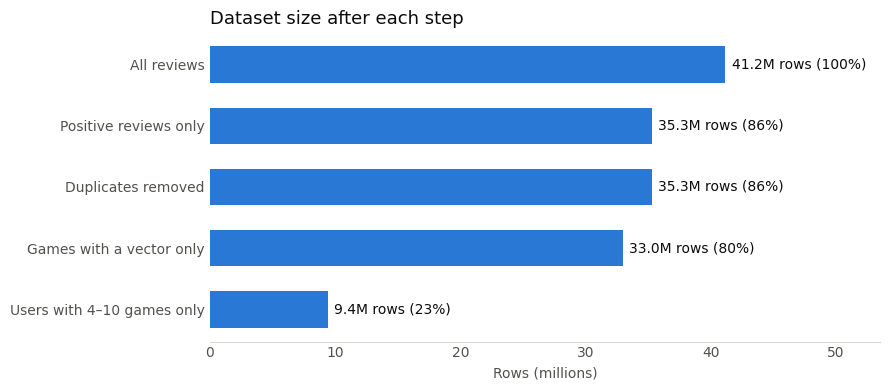

In [6]:
import matplotlib.pyplot as plt

labels = list(step_sizes)
sizes = list(step_sizes.values())
total = sizes[0]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(labels, [s / 1e6 for s in sizes], color="#2a78d6", height=0.6)
ax.invert_yaxis()  # first step at the top

for bar, size in zip(bars, sizes):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{size / 1e6:.1f}M rows ({size / total:.0%})",
            va="center", color="#0b0b0b")

ax.set_title("Dataset size after each step", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Rows (millions)", color="#52514e")
ax.set_xlim(0, total / 1e6 * 1.3)
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()

## 6. Save the prepared dataset

Evaluation uses a chronological leave-one-out split: each user's **most recent** liked game is held out as the `target`, and every earlier game becomes the `history` the recommender gets as input. This matches real use, where we predict the next game a user will like from the ones they liked before.

The final dataset is saved to `data/external/recommendations_ready.json`:

```json
{"<user_id>": {"history": [app_id, app_id, ...], "target": app_id}, ...}
```

- `history`: the user's liked games without the most recent one, oldest first
- `target`: the most recent liked game, which the recommender should suggest

Games are sorted by review `date`. When a user reviewed several games on the same day, `review_id` breaks the tie, so the split is the same on every run. JSON keys are always strings, so `user_id` is stored as a string and the `app_id`s stay integers. Because of the step 4 filter, every `history` has at least `MIN_GAMES_PER_USER - 1` = 3 games.

In [7]:
import json

OUTPUT_PATH = Path("../../../data/external/recommendations_ready.json")

user_games = (
    df.sort_values(["user_id", "date", "review_id"])
    .groupby("user_id")["app_id"]
    .agg(list)
)
recommendations = {
    str(user_id): {
        "history": [int(a) for a in app_ids[:-1]],
        "target": int(app_ids[-1]),
    }
    for user_id, app_ids in user_games.items()
}

with open(OUTPUT_PATH, "w") as f:
    json.dump(recommendations, f, separators=(",", ":"))

print(f"saved {len(recommendations):,} users to {OUTPUT_PATH} ({OUTPUT_PATH.stat().st_size / 1024**2:,.0f} MB)")

saved 1,652,783 users to ..\..\..\data\external\recommendations_ready.json (115 MB)


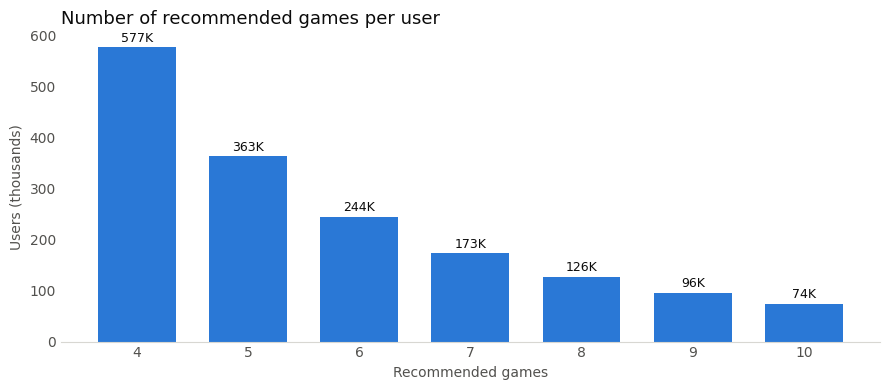

In [8]:
# history + the held-out target = all games the user recommended
games_per_user = pd.Series([len(user["history"]) + 1 for user in recommendations.values()])

# small counts get their own bar, larger ones are grouped into ranges;
# edges above the largest count are dropped so the bins always increase
max_games = games_per_user.max()
edges = [3, 4, 5, 6, 7, 8, 9, 10, 20, 50]
bins = [e for e in edges if e < max_games] + [max_games]

def bin_label(lo, hi):
    return str(hi) if hi - lo == 1 else f"{lo + 1}–{hi}"

bin_labels = [bin_label(lo, hi) for lo, hi in zip(bins[:-1], bins[1:])]
users_per_bin = pd.cut(games_per_user, bins=bins, labels=bin_labels).value_counts(sort=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(users_per_bin.index.astype(str), users_per_bin.values / 1e3, color="#2a78d6", width=0.7)

for bar, count in zip(bars, users_per_bin.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"{count / 1e3:.0f}K", ha="center", va="bottom", color="#0b0b0b", fontsize=9)

ax.set_title("Number of recommended games per user", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Recommended games", color="#52514e")
ax.set_ylabel("Users (thousands)", color="#52514e")
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()